In [1]:
from pathlib import Path
from collections import Counter
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [2]:
DATA_DIR = Path("Sequential_Peptides")

train_df = pd.read_csv(
    DATA_DIR / "train_seqs.csv"
)

valid_df = pd.read_csv(
    DATA_DIR / "valid_seqs.csv"
)

test_df = pd.read_csv(
    DATA_DIR / "test_seqs.csv"
)

for dataframe in [
    train_df,
    valid_df,
    test_df
]:
    dataframe.drop(
        columns=["Unnamed: 0"],
        errors="ignore",
        inplace=True
    )

print("Original shapes:")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Original shapes:
Train: (54159, 2)
Validation: (4000, 2)
Test: (4000, 2)


,Feature,Label
0,NACFTMR,1.687
1,MQLVD,1.710
2,RTCERVNPLE,1.659
3,TWCCTTF,2.020
4,LAPRPQGLKG,1.524


In [3]:
train_sequences = set(train_df["Feature"])

valid_df = valid_df[
    ~valid_df["Feature"].isin(train_sequences)
].copy()

test_df = test_df[
    ~test_df["Feature"].isin(train_sequences)
].copy()

test_df = test_df[
    ~test_df["Feature"].isin(
        set(valid_df["Feature"])
    )
].copy()

print("Clean shapes:")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

Clean shapes:
Train: (54159, 2)
Validation: (3999, 2)
Test: (3997, 2)


In [4]:
AMINO_ACIDS = list(
    "ACDEFGHIKLMNPQRSTVWY"
)

AA_TO_INDEX = {
    amino_acid: index
    for index, amino_acid
    in enumerate(AMINO_ACIDS)
}

MAX_LENGTH = 10

def encode_aac(
    sequence: str
) -> np.ndarray:
    """
    Encode a peptide as a 20-dimensional
    amino-acid composition vector.
    """
    sequence = str(
        sequence
    ).strip().upper()

    if len(sequence) == 0:
        raise ValueError(
            "Empty peptide sequence encountered."
        )

    counts = Counter(sequence)

    return np.array(
        [
            counts.get(amino_acid, 0)
            / len(sequence)
            for amino_acid in AMINO_ACIDS
        ],
        dtype=np.float32
    )

In [5]:
def encode_positional_one_hot(
    sequence: str
) -> np.ndarray:
    """
    Encode a peptide as a flattened
    10 x 20 positional one-hot vector.
    """
    sequence = str(
        sequence
    ).strip().upper()

    if len(sequence) == 0:
        raise ValueError(
            "Empty peptide sequence encountered."
        )

    if len(sequence) > MAX_LENGTH:
        raise ValueError(
            f"Sequence is too long: {sequence}"
        )

    encoding = np.zeros(
        (
            MAX_LENGTH,
            len(AMINO_ACIDS)
        ),
        dtype=np.float32
    )

    for position, amino_acid in enumerate(
        sequence
    ):
        if amino_acid not in AA_TO_INDEX:
            raise ValueError(
                f"Unexpected amino acid: "
                f"{amino_acid}"
            )

        encoding[
            position,
            AA_TO_INDEX[amino_acid]
        ] = 1.0

    return encoding.flatten()

In [6]:
def encode_combined_features(
    sequence: str
) -> np.ndarray:
    """
    Combine AAC, positional one-hot
    and normalized sequence length.
    """
    sequence = str(
        sequence
    ).strip().upper()

    aac_features = encode_aac(sequence)

    positional_features = (
        encode_positional_one_hot(
            sequence
        )
    )

    normalized_length = np.array(
        [
            len(sequence) / MAX_LENGTH
        ],
        dtype=np.float32
    )

    return np.concatenate(
        [
            aac_features,
            positional_features,
            normalized_length
        ]
    )

In [7]:
def build_combined_feature_matrix(
    dataframe: pd.DataFrame
) -> np.ndarray:
    return np.vstack(
        dataframe["Feature"].map(
            encode_combined_features
        )
    )

X_train = build_combined_feature_matrix(
    train_df
)

X_valid = build_combined_feature_matrix(
    valid_df
)

X_test = build_combined_feature_matrix(
    test_df
)

y_train = train_df[
    "Label"
].to_numpy(
    dtype=np.float32
)

y_valid = valid_df[
    "Label"
].to_numpy(
    dtype=np.float32
)

y_test = test_df[
    "Label"
].to_numpy(
    dtype=np.float32
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)
print("y_test:", y_test.shape)

X_train: (54159, 221)
X_valid: (3999, 221)
X_test: (3997, 221)
y_train: (54159,)
y_valid: (3999,)
y_test: (3997,)


In [8]:
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (
    y_train - y_mean
) / y_std

y_valid_scaled = (
    y_valid - y_mean
) / y_std

y_test_scaled = (
    y_test - y_mean
) / y_std

print("Training-label mean:", y_mean)
print("Training-label std:", y_std)

print(
    "Scaled training-label mean:",
    y_train_scaled.mean()
)

print(
    "Scaled training-label std:",
    y_train_scaled.std()
)

Training-label mean: 1.7387624
Training-label std: 0.21119417
Scaled training-label mean: -5.620725e-08
Scaled training-label std: 1.0


In [9]:
def create_tensor_dataset(
    X: np.ndarray,
    y: np.ndarray
) -> TensorDataset:
    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y,
        dtype=torch.float32
    ).reshape(-1, 1)

    return TensorDataset(
        X_tensor,
        y_tensor
    )

train_dataset = create_tensor_dataset(
    X_train,
    y_train_scaled
)

valid_dataset = create_tensor_dataset(
    X_valid,
    y_valid_scaled
)

test_dataset = create_tensor_dataset(
    X_test,
    y_test_scaled
)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

Training batches: 212
Validation batches: 16
Test batches: 16


In [10]:
class MLPRegressor(nn.Module):
    def __init__(
        self,
        input_dim: int
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(
                input_dim,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                p=0.10
            ),

            nn.Linear(
                256,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                p=0.10
            ),

            nn.Linear(
                128,
                1
            )
        )

    def forward(
        self,
        X: torch.Tensor
    ) -> torch.Tensor:
        return self.network(X)

model = MLPRegressor(
    input_dim=X_train.shape[1]
).to(device)

In [11]:
loss_function = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

In [12]:
def predict_scaled_values(
    model: nn.Module,
    data_loader: DataLoader
) -> np.ndarray:
    model.eval()

    predictions = []

    with torch.no_grad():
        for X_batch, _ in data_loader:
            X_batch = X_batch.to(device)

            prediction_batch = model(
                X_batch
            )

            predictions.append(
                prediction_batch
                .cpu()
                .numpy()
                .reshape(-1)
            )

    return np.concatenate(
        predictions
    )


def restore_original_scale(
    scaled_values: np.ndarray
) -> np.ndarray:
    return (
        scaled_values * y_std
        + y_mean
    )


def calculate_metrics(
    true_values: np.ndarray,
    predictions: np.ndarray
) -> dict:
    return {
        "MAE": mean_absolute_error(
            true_values,
            predictions
        ),

        "RMSE": mean_squared_error(
            true_values,
            predictions
        ) ** 0.5,

        "R2": r2_score(
            true_values,
            predictions
        )
    }

In [13]:
MAX_EPOCHS = 100
PATIENCE = 12

best_valid_mae = float("inf")
best_epoch = None
best_model_state = None

training_history = []

for epoch in range(
    1,
    MAX_EPOCHS + 1
):
    model.train()

    total_training_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = loss_function(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_training_loss += (
            loss.item()
            * len(X_batch)
        )

    average_training_loss = (
        total_training_loss
        / len(train_dataset)
    )

    valid_scaled_predictions = (
        predict_scaled_values(
            model,
            valid_loader
        )
    )

    valid_predictions = (
        restore_original_scale(
            valid_scaled_predictions
        )
    )

    valid_metrics = calculate_metrics(
        y_valid,
        valid_predictions
    )

    training_history.append({
        "epoch": epoch,
        "training_MSE_scaled":
            average_training_loss,
        "valid_MAE":
            valid_metrics["MAE"],
        "valid_RMSE":
            valid_metrics["RMSE"],
        "valid_R2":
            valid_metrics["R2"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train MSE: "
        f"{average_training_loss:.5f} | "
        f"Valid MAE: "
        f"{valid_metrics['MAE']:.5f} | "
        f"Valid R2: "
        f"{valid_metrics['R2']:.5f}"
    )

    if valid_metrics["MAE"] < best_valid_mae:
        best_valid_mae = (
            valid_metrics["MAE"]
        )

        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

    elif epoch - best_epoch >= PATIENCE:
        print(
            "\nEarly stopping triggered."
        )
        break

Epoch 001 | Train MSE: 0.28101 | Valid MAE: 0.04942 | Valid R2: 0.90435
Epoch 002 | Train MSE: 0.08552 | Valid MAE: 0.04514 | Valid R2: 0.92119
Epoch 003 | Train MSE: 0.07265 | Valid MAE: 0.04385 | Valid R2: 0.92590
Epoch 004 | Train MSE: 0.06522 | Valid MAE: 0.04302 | Valid R2: 0.92919
Epoch 005 | Train MSE: 0.05962 | Valid MAE: 0.04276 | Valid R2: 0.93025
Epoch 006 | Train MSE: 0.05574 | Valid MAE: 0.04309 | Valid R2: 0.92923
Epoch 007 | Train MSE: 0.05261 | Valid MAE: 0.04147 | Valid R2: 0.93451
Epoch 008 | Train MSE: 0.05075 | Valid MAE: 0.04203 | Valid R2: 0.93223
Epoch 009 | Train MSE: 0.04856 | Valid MAE: 0.04181 | Valid R2: 0.93405
Epoch 010 | Train MSE: 0.04682 | Valid MAE: 0.04191 | Valid R2: 0.93396
Epoch 011 | Train MSE: 0.04566 | Valid MAE: 0.04139 | Valid R2: 0.93456
Epoch 012 | Train MSE: 0.04437 | Valid MAE: 0.04191 | Valid R2: 0.93311
Epoch 013 | Train MSE: 0.04285 | Valid MAE: 0.04142 | Valid R2: 0.93458
Epoch 014 | Train MSE: 0.04196 | Valid MAE: 0.04227 | Valid R2: 

In [14]:
model.load_state_dict(
    best_model_state
)

test_scaled_predictions = (
    predict_scaled_values(
        model,
        test_loader
    )
)

test_predictions = (
    restore_original_scale(
        test_scaled_predictions
    )
)

test_metrics = calculate_metrics(
    y_test,
    test_predictions
)

print("Best epoch:", best_epoch)

print("\n===== MLP Test Metrics =====")
print("MAE:", test_metrics["MAE"])
print("RMSE:", test_metrics["RMSE"])
print("R2:", test_metrics["R2"])

Best epoch: 11

===== MLP Test Metrics =====
MAE: 0.041304927319288254
RMSE: 0.0525376394142935
R2: 0.9380878210067749


In [15]:
mlp_result_df = pd.DataFrame([
    {
        "encoding":
            "Combined Features",
        "model":
            "MLP",
        "test_MAE":
            test_metrics["MAE"],
        "test_RMSE":
            test_metrics["RMSE"],
        "test_R2":
            test_metrics["R2"],
        "best_epoch":
            best_epoch
    }
])

display(mlp_result_df)

,encoding,model,test_MAE,test_RMSE,test_R2,best_epoch
0,Combined Features,MLP,0.041305,0.052538,0.938088,11


In [16]:
history_df = pd.DataFrame(
    training_history
)

In [17]:
results_dir = Path("results")
figures_dir = Path("figures")

results_dir.mkdir(
    exist_ok=True
)

figures_dir.mkdir(
    exist_ok=True
)

mlp_result_df.to_csv(
    results_dir
    / "mlp_combined_features.csv",
    index=False
)

history_df.to_csv(
    results_dir
    / "mlp_training_history.csv",
    index=False
)

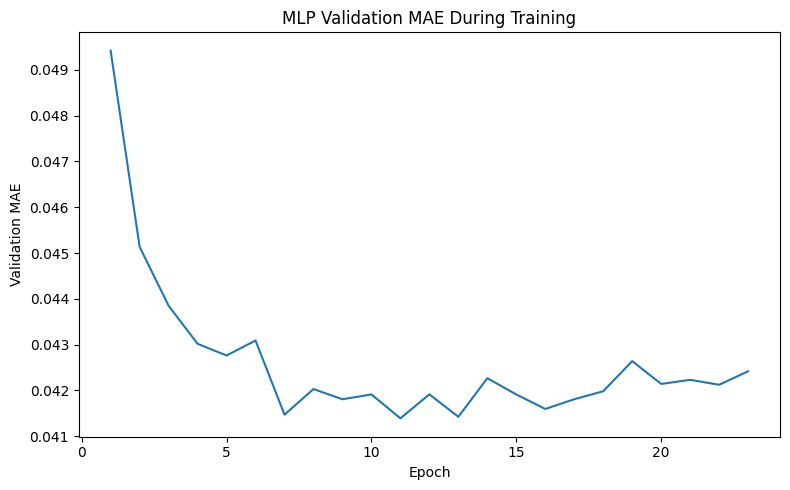

In [18]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["valid_MAE"]
)

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title(
    "MLP Validation MAE During Training"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "mlp_validation_mae.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

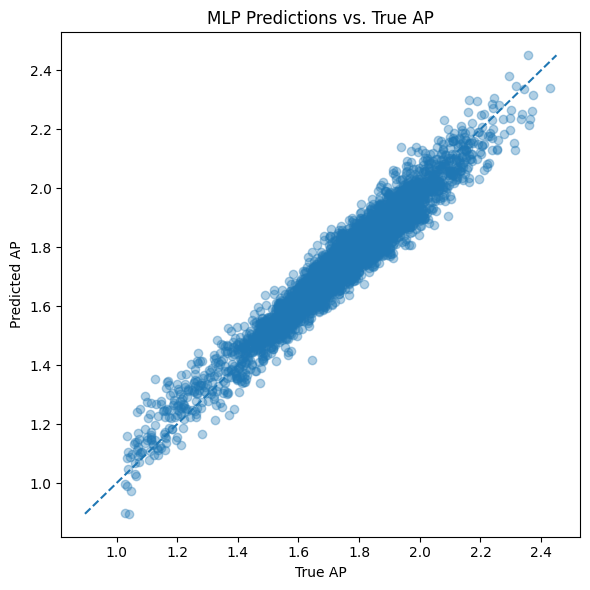

In [19]:
plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.35
)

minimum_value = min(
    y_test.min(),
    test_predictions.min()
)

maximum_value = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [
        minimum_value,
        maximum_value
    ],
    [
        minimum_value,
        maximum_value
    ],
    linestyle="--"
)

plt.xlabel("True AP")
plt.ylabel("Predicted AP")
plt.title(
    "MLP Predictions vs. True AP"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "mlp_predictions_vs_true_ap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [20]:
PAD_INDEX = 0

AA_TO_TOKEN = {
    amino_acid: index + 1
    for index, amino_acid
    in enumerate(AMINO_ACIDS)
}

VOCAB_SIZE = len(AMINO_ACIDS) + 1

print("Vocabulary size:", VOCAB_SIZE)
print("Padding index:", PAD_INDEX)
print("Token mapping:")
print(AA_TO_TOKEN)

Vocabulary size: 21
Padding index: 0
Token mapping:
{'A': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'P': 13, 'Q': 14, 'R': 15, 'S': 16, 'T': 17, 'V': 18, 'W': 19, 'Y': 20}


In [21]:
def encode_token_sequence(
    sequence: str
):
    """
    Convert a peptide sequence into:
    1. a padded token vector of length MAX_LENGTH;
    2. the original sequence length.
    """
    sequence = str(
        sequence
    ).strip().upper()

    if len(sequence) == 0:
        raise ValueError(
            "Empty peptide sequence encountered."
        )

    if len(sequence) > MAX_LENGTH:
        raise ValueError(
            f"Sequence is too long: {sequence}"
        )

    token_ids = []

    for amino_acid in sequence:
        if amino_acid not in AA_TO_TOKEN:
            raise ValueError(
                f"Unexpected amino acid: {amino_acid}"
            )

        token_ids.append(
            AA_TO_TOKEN[amino_acid]
        )

    original_length = len(token_ids)

    padded_tokens = (
        token_ids
        + [PAD_INDEX]
        * (MAX_LENGTH - original_length)
    )

    return np.array(
        padded_tokens,
        dtype=np.int64
    ), original_length

In [22]:
def build_token_matrices(
    dataframe: pd.DataFrame
):
    encoded_samples = [
        encode_token_sequence(sequence)
        for sequence
        in dataframe["Feature"]
    ]

    token_matrix = np.vstack(
        [
            sample[0]
            for sample
            in encoded_samples
        ]
    )

    sequence_lengths = np.array(
        [
            sample[1]
            for sample
            in encoded_samples
        ],
        dtype=np.int64
    )

    return (
        token_matrix,
        sequence_lengths
    )

In [23]:
X_train_tokens, train_lengths = (
    build_token_matrices(train_df)
)

X_valid_tokens, valid_lengths = (
    build_token_matrices(valid_df)
)

X_test_tokens, test_lengths = (
    build_token_matrices(test_df)
)

print(
    "X_train_tokens:",
    X_train_tokens.shape
)

print(
    "train_lengths:",
    train_lengths.shape
)

print(
    "First token sequence:",
    X_train_tokens[0]
)

print(
    "First sequence length:",
    train_lengths[0]
)

X_train_tokens: (54159, 10)
train_lengths: (54159,)
First token sequence: [12  1  2  5 17 11 15  0  0  0]
First sequence length: 7


In [24]:
def create_sequence_dataset(
    token_matrix: np.ndarray,
    sequence_lengths: np.ndarray,
    scaled_labels: np.ndarray
) -> TensorDataset:
    token_tensor = torch.tensor(
        token_matrix,
        dtype=torch.long
    )

    length_tensor = torch.tensor(
        sequence_lengths,
        dtype=torch.long
    )

    label_tensor = torch.tensor(
        scaled_labels,
        dtype=torch.float32
    ).reshape(-1, 1)

    return TensorDataset(
        token_tensor,
        length_tensor,
        label_tensor
    )

In [25]:
train_seq_dataset = (
    create_sequence_dataset(
        X_train_tokens,
        train_lengths,
        y_train_scaled
    )
)

valid_seq_dataset = (
    create_sequence_dataset(
        X_valid_tokens,
        valid_lengths,
        y_valid_scaled
    )
)

test_seq_dataset = (
    create_sequence_dataset(
        X_test_tokens,
        test_lengths,
        y_test_scaled
    )
)

In [26]:
SEQ_BATCH_SIZE = 256

train_seq_loader = DataLoader(
    train_seq_dataset,
    batch_size=SEQ_BATCH_SIZE,
    shuffle=True
)

valid_seq_loader = DataLoader(
    valid_seq_dataset,
    batch_size=SEQ_BATCH_SIZE,
    shuffle=False
)

test_seq_loader = DataLoader(
    test_seq_dataset,
    batch_size=SEQ_BATCH_SIZE,
    shuffle=False
)

print(
    "Training batches:",
    len(train_seq_loader)
)

print(
    "Validation batches:",
    len(valid_seq_loader)
)

print(
    "Test batches:",
    len(test_seq_loader)
)

Training batches: 212
Validation batches: 16
Test batches: 16


In [27]:
class LSTMRegressor(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 32,
        hidden_dim: int = 64,
        dropout_rate: float = 0.10
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_INDEX
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.output_head = nn.Sequential(
            nn.Linear(
                hidden_dim,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                p=dropout_rate
            ),

            nn.Linear(
                64,
                1
            )
        )

    def forward(
        self,
        token_ids: torch.Tensor,
        sequence_lengths: torch.Tensor
    ) -> torch.Tensor:
        embedded_tokens = self.embedding(
            token_ids
        )

        packed_tokens = (
            nn.utils.rnn.pack_padded_sequence(
                embedded_tokens,
                sequence_lengths.cpu(),
                batch_first=True,
                enforce_sorted=False
            )
        )

        _, (
            final_hidden_state,
            _
        ) = self.lstm(
            packed_tokens
        )

        sequence_representation = (
            final_hidden_state[-1]
        )

        return self.output_head(
            sequence_representation
        )

In [28]:
lstm_model = LSTMRegressor(
    vocab_size=VOCAB_SIZE
).to(device)

In [29]:
def predict_lstm_scaled_values(
    model: nn.Module,
    data_loader: DataLoader
) -> np.ndarray:
    model.eval()

    predictions = []

    with torch.no_grad():
        for (
            token_batch,
            length_batch,
            _
        ) in data_loader:
            token_batch = token_batch.to(
                device
            )

            length_batch = length_batch.to(
                device
            )

            prediction_batch = model(
                token_batch,
                length_batch
            )

            predictions.append(
                prediction_batch
                .cpu()
                .numpy()
                .reshape(-1)
            )

    return np.concatenate(
        predictions
    )

In [30]:
lstm_loss_function = nn.MSELoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

In [31]:
LSTM_MAX_EPOCHS = 80
LSTM_PATIENCE = 12

best_lstm_valid_mae = float("inf")
best_lstm_epoch = None
best_lstm_state = None

lstm_training_history = []

for epoch in range(
    1,
    LSTM_MAX_EPOCHS + 1
):
    lstm_model.train()

    total_training_loss = 0.0

    for (
        token_batch,
        length_batch,
        label_batch
    ) in train_seq_loader:
        token_batch = token_batch.to(
            device
        )

        length_batch = length_batch.to(
            device
        )

        label_batch = label_batch.to(
            device
        )

        lstm_optimizer.zero_grad()

        predictions = lstm_model(
            token_batch,
            length_batch
        )

        loss = lstm_loss_function(
            predictions,
            label_batch
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        lstm_optimizer.step()

        total_training_loss += (
            loss.item()
            * len(token_batch)
        )

    average_training_loss = (
        total_training_loss
        / len(train_seq_dataset)
    )

    valid_scaled_predictions = (
        predict_lstm_scaled_values(
            lstm_model,
            valid_seq_loader
        )
    )

    valid_predictions = (
        restore_original_scale(
            valid_scaled_predictions
        )
    )

    valid_metrics = calculate_metrics(
        y_valid,
        valid_predictions
    )

    lstm_training_history.append({
        "epoch": epoch,
        "training_MSE_scaled":
            average_training_loss,
        "valid_MAE":
            valid_metrics["MAE"],
        "valid_RMSE":
            valid_metrics["RMSE"],
        "valid_R2":
            valid_metrics["R2"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train MSE: "
        f"{average_training_loss:.5f} | "
        f"Valid MAE: "
        f"{valid_metrics['MAE']:.5f} | "
        f"Valid R2: "
        f"{valid_metrics['R2']:.5f}"
    )

    if (
        valid_metrics["MAE"]
        < best_lstm_valid_mae
    ):
        best_lstm_valid_mae = (
            valid_metrics["MAE"]
        )

        best_lstm_epoch = epoch

        best_lstm_state = copy.deepcopy(
            lstm_model.state_dict()
        )

    elif (
        epoch - best_lstm_epoch
        >= LSTM_PATIENCE
    ):
        print(
            "\nEarly stopping triggered."
        )

        break

Epoch 001 | Train MSE: 0.34119 | Valid MAE: 0.06473 | Valid R2: 0.84056
Epoch 002 | Train MSE: 0.11894 | Valid MAE: 0.05181 | Valid R2: 0.89968
Epoch 003 | Train MSE: 0.09169 | Valid MAE: 0.04789 | Valid R2: 0.91347
Epoch 004 | Train MSE: 0.08187 | Valid MAE: 0.04521 | Valid R2: 0.92208
Epoch 005 | Train MSE: 0.07528 | Valid MAE: 0.04444 | Valid R2: 0.92419
Epoch 006 | Train MSE: 0.07302 | Valid MAE: 0.04348 | Valid R2: 0.92853
Epoch 007 | Train MSE: 0.06948 | Valid MAE: 0.04267 | Valid R2: 0.93026
Epoch 008 | Train MSE: 0.06732 | Valid MAE: 0.04275 | Valid R2: 0.93117
Epoch 009 | Train MSE: 0.06703 | Valid MAE: 0.04443 | Valid R2: 0.92565
Epoch 010 | Train MSE: 0.06529 | Valid MAE: 0.04220 | Valid R2: 0.93202
Epoch 011 | Train MSE: 0.06389 | Valid MAE: 0.04134 | Valid R2: 0.93500
Epoch 012 | Train MSE: 0.06285 | Valid MAE: 0.04141 | Valid R2: 0.93477
Epoch 013 | Train MSE: 0.06200 | Valid MAE: 0.04109 | Valid R2: 0.93572
Epoch 014 | Train MSE: 0.06013 | Valid MAE: 0.04183 | Valid R2: 

In [32]:
lstm_model.load_state_dict(
    best_lstm_state
)

test_scaled_predictions_lstm = (
    predict_lstm_scaled_values(
        lstm_model,
        test_seq_loader
    )
)

test_predictions_lstm = (
    restore_original_scale(
        test_scaled_predictions_lstm
    )
)

lstm_test_metrics = calculate_metrics(
    y_test,
    test_predictions_lstm
)

print("Best LSTM epoch:", best_lstm_epoch)

print("\n===== LSTM Test Metrics =====")

print(
    "MAE:",
    lstm_test_metrics["MAE"]
)

print(
    "RMSE:",
    lstm_test_metrics["RMSE"]
)

print(
    "R2:",
    lstm_test_metrics["R2"]
)

Best LSTM epoch: 41

===== LSTM Test Metrics =====
MAE: 0.03847586363554001
RMSE: 0.048811471006315166
R2: 0.9465584754943848


In [33]:
lstm_result_df = pd.DataFrame([
    {
        "encoding":
            "Token Sequence",
        "model":
            "LSTM",
        "test_MAE":
            lstm_test_metrics["MAE"],
        "test_RMSE":
            lstm_test_metrics["RMSE"],
        "test_R2":
            lstm_test_metrics["R2"],
        "best_epoch":
            best_lstm_epoch
    }
])

display(lstm_result_df)

,encoding,model,test_MAE,test_RMSE,test_R2,best_epoch
0,Token Sequence,LSTM,0.038476,0.048811,0.946558,41


In [34]:
lstm_history_df = pd.DataFrame(
    lstm_training_history
)

lstm_result_df.to_csv(
    results_dir / "lstm_token_sequence.csv",
    index=False
)

lstm_history_df.to_csv(
    results_dir / "lstm_training_history.csv",
    index=False
)

torch.save(
    best_lstm_state,
    results_dir / "best_lstm_model.pt"
)

print("LSTM results saved.")

LSTM results saved.


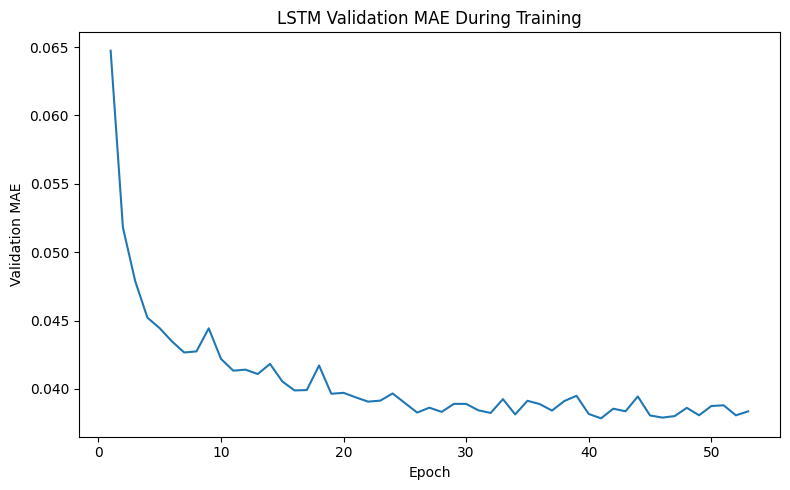

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    lstm_history_df["epoch"],
    lstm_history_df["valid_MAE"]
)

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title("LSTM Validation MAE During Training")

plt.tight_layout()

plt.savefig(
    figures_dir / "lstm_validation_mae.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

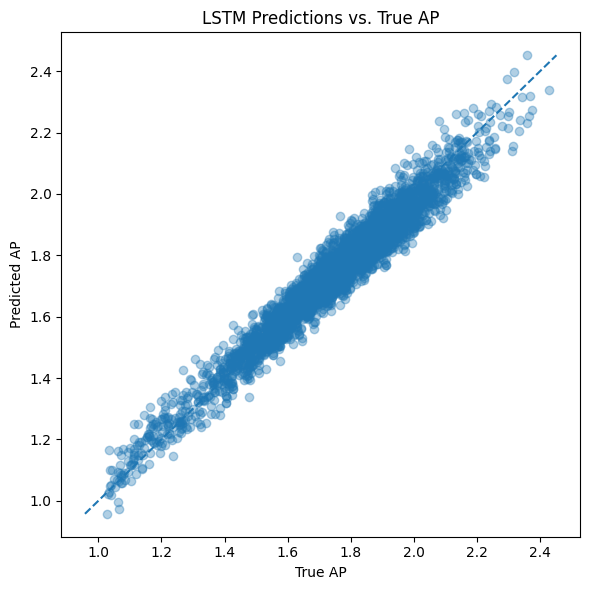

In [36]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    test_predictions_lstm,
    alpha=0.35
)

minimum_value = min(
    y_test.min(),
    test_predictions_lstm.min()
)

maximum_value = max(
    y_test.max(),
    test_predictions_lstm.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("True AP")
plt.ylabel("Predicted AP")
plt.title("LSTM Predictions vs. True AP")

plt.tight_layout()

plt.savefig(
    figures_dir / "lstm_predictions_vs_true_ap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [37]:
class TransformerRegressor(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        max_length: int,
        embedding_dim: int = 64,
        num_heads: int = 4,
        num_layers: int = 2,
        feedforward_dim: int = 128,
        dropout_rate: float = 0.10
    ):
        super().__init__()

        if embedding_dim % num_heads != 0:
            raise ValueError(
                "embedding_dim must be divisible by num_heads."
            )

        self.token_embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_INDEX
        )

        self.position_embedding = nn.Embedding(
            num_embeddings=max_length,
            embedding_dim=embedding_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout_rate,
            activation="gelu",
            batch_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=num_layers
        )

        self.output_head = nn.Sequential(
            nn.LayerNorm(embedding_dim),

            nn.Linear(
                embedding_dim,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                p=dropout_rate
            ),

            nn.Linear(
                64,
                1
            )
        )

    def forward(
        self,
        token_ids: torch.Tensor,
        sequence_lengths: torch.Tensor
    ) -> torch.Tensor:
        batch_size, sequence_length = token_ids.shape

        position_ids = torch.arange(
            sequence_length,
            device=token_ids.device
        ).unsqueeze(0)

        token_features = self.token_embedding(
            token_ids
        )

        position_features = self.position_embedding(
            position_ids
        )

        embedded_tokens = (
            token_features
            + position_features
        )

        padding_mask = (
            token_ids == PAD_INDEX
        )

        encoded_tokens = self.transformer_encoder(
            embedded_tokens,
            src_key_padding_mask=padding_mask
        )

        non_padding_mask = (
            ~padding_mask
        ).unsqueeze(-1).type_as(
            encoded_tokens
        )

        summed_representation = (
            encoded_tokens
            * non_padding_mask
        ).sum(dim=1)

        valid_token_count = (
            sequence_lengths
            .unsqueeze(1)
            .clamp_min(1)
            .type_as(encoded_tokens)
        )

        pooled_representation = (
            summed_representation
            / valid_token_count
        )

        return self.output_head(
            pooled_representation
        )

In [38]:
transformer_model = TransformerRegressor(
    vocab_size=VOCAB_SIZE,
    max_length=MAX_LENGTH
).to(device)

In [39]:
def predict_transformer_scaled_values(
    model: nn.Module,
    data_loader: DataLoader
) -> np.ndarray:
    model.eval()

    predictions = []

    with torch.no_grad():
        for (
            token_batch,
            length_batch,
            _
        ) in data_loader:
            token_batch = token_batch.to(
                device
            )

            length_batch = length_batch.to(
                device
            )

            prediction_batch = model(
                token_batch,
                length_batch
            )

            predictions.append(
                prediction_batch
                .cpu()
                .numpy()
                .reshape(-1)
            )

    return np.concatenate(
        predictions
    )

In [40]:
transformer_loss_function = nn.MSELoss()

transformer_optimizer = torch.optim.AdamW(
    transformer_model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

In [41]:
TRANSFORMER_MAX_EPOCHS = 80
TRANSFORMER_PATIENCE = 12

best_transformer_valid_mae = float("inf")
best_transformer_epoch = None
best_transformer_state = None

transformer_training_history = []

for epoch in range(
    1,
    TRANSFORMER_MAX_EPOCHS + 1
):
    transformer_model.train()

    total_training_loss = 0.0

    for (
        token_batch,
        length_batch,
        label_batch
    ) in train_seq_loader:
        token_batch = token_batch.to(
            device
        )

        length_batch = length_batch.to(
            device
        )

        label_batch = label_batch.to(
            device
        )

        transformer_optimizer.zero_grad()

        predictions = transformer_model(
            token_batch,
            length_batch
        )

        loss = transformer_loss_function(
            predictions,
            label_batch
        )

        loss.backward()

        nn.utils.clip_grad_norm_(
            transformer_model.parameters(),
            max_norm=1.0
        )

        transformer_optimizer.step()

        total_training_loss += (
            loss.item()
            * len(token_batch)
        )

    average_training_loss = (
        total_training_loss
        / len(train_seq_dataset)
    )

    valid_scaled_predictions = (
        predict_transformer_scaled_values(
            transformer_model,
            valid_seq_loader
        )
    )

    valid_predictions = (
        restore_original_scale(
            valid_scaled_predictions
        )
    )

    valid_metrics = calculate_metrics(
        y_valid,
        valid_predictions
    )

    transformer_training_history.append({
        "epoch": epoch,
        "training_MSE_scaled":
            average_training_loss,
        "valid_MAE":
            valid_metrics["MAE"],
        "valid_RMSE":
            valid_metrics["RMSE"],
        "valid_R2":
            valid_metrics["R2"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train MSE: "
        f"{average_training_loss:.5f} | "
        f"Valid MAE: "
        f"{valid_metrics['MAE']:.5f} | "
        f"Valid R2: "
        f"{valid_metrics['R2']:.5f}"
    )

    if (
        valid_metrics["MAE"]
        < best_transformer_valid_mae
    ):
        best_transformer_valid_mae = (
            valid_metrics["MAE"]
        )

        best_transformer_epoch = epoch

        best_transformer_state = copy.deepcopy(
            transformer_model.state_dict()
        )

    elif (
        epoch - best_transformer_epoch
        >= TRANSFORMER_PATIENCE
    ):
        print(
            "\nEarly stopping triggered."
        )

        break

C:\Users\yzy27\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(


Epoch 001 | Train MSE: 0.20219 | Valid MAE: 0.04708 | Valid R2: 0.91438
Epoch 002 | Train MSE: 0.08921 | Valid MAE: 0.04485 | Valid R2: 0.92232
Epoch 003 | Train MSE: 0.08083 | Valid MAE: 0.04492 | Valid R2: 0.92369
Epoch 004 | Train MSE: 0.07555 | Valid MAE: 0.04436 | Valid R2: 0.92604
Epoch 005 | Train MSE: 0.07273 | Valid MAE: 0.04103 | Valid R2: 0.93560
Epoch 006 | Train MSE: 0.06959 | Valid MAE: 0.04085 | Valid R2: 0.93664
Epoch 007 | Train MSE: 0.06771 | Valid MAE: 0.04118 | Valid R2: 0.93603
Epoch 008 | Train MSE: 0.06644 | Valid MAE: 0.04067 | Valid R2: 0.93755
Epoch 009 | Train MSE: 0.06564 | Valid MAE: 0.04010 | Valid R2: 0.93964
Epoch 010 | Train MSE: 0.06381 | Valid MAE: 0.04018 | Valid R2: 0.93892
Epoch 011 | Train MSE: 0.06320 | Valid MAE: 0.03925 | Valid R2: 0.94178
Epoch 012 | Train MSE: 0.06223 | Valid MAE: 0.03957 | Valid R2: 0.94076
Epoch 013 | Train MSE: 0.06155 | Valid MAE: 0.03958 | Valid R2: 0.94059
Epoch 014 | Train MSE: 0.06008 | Valid MAE: 0.03925 | Valid R2: 

In [42]:
transformer_model.load_state_dict(
    best_transformer_state
)

test_scaled_predictions_transformer = (
    predict_transformer_scaled_values(
        transformer_model,
        test_seq_loader
    )
)

test_predictions_transformer = (
    restore_original_scale(
        test_scaled_predictions_transformer
    )
)

transformer_test_metrics = calculate_metrics(
    y_test,
    test_predictions_transformer
)

print(
    "Best Transformer epoch:",
    best_transformer_epoch
)

print(
    "\n===== Transformer Test Metrics ====="
)

print(
    "MAE:",
    transformer_test_metrics["MAE"]
)

print(
    "RMSE:",
    transformer_test_metrics["RMSE"]
)

print(
    "R2:",
    transformer_test_metrics["R2"]
)

Best Transformer epoch: 25

===== Transformer Test Metrics =====
MAE: 0.03792214393615723
RMSE: 0.048025726591313725
R2: 0.9482651948928833


In [43]:
transformer_result_df = pd.DataFrame([
    {
        "encoding":
            "Token Sequence",
        "model":
            "Transformer",
        "test_MAE":
            transformer_test_metrics["MAE"],
        "test_RMSE":
            transformer_test_metrics["RMSE"],
        "test_R2":
            transformer_test_metrics["R2"],
        "best_epoch":
            best_transformer_epoch
    }
])

display(transformer_result_df)

,encoding,model,test_MAE,test_RMSE,test_R2,best_epoch
0,Token Sequence,Transformer,0.037922,0.048026,0.948265,25


In [44]:
neural_network_comparison_df = pd.concat(
    [
        mlp_result_df,
        lstm_result_df,
        transformer_result_df
    ],
    ignore_index=True
)

display(
    neural_network_comparison_df[
        [
            "encoding",
            "model",
            "test_MAE",
            "test_RMSE",
            "test_R2",
            "best_epoch"
        ]
    ].sort_values(
        "test_MAE"
    )
)

,encoding,model,test_MAE,test_RMSE,test_R2,best_epoch
2,Token Sequence,Transformer,0.037922,0.048026,0.948265,25
1,Token Sequence,LSTM,0.038476,0.048811,0.946558,41
0,Combined Features,MLP,0.041305,0.052538,0.938088,11


In [45]:
transformer_history_df = pd.DataFrame(
    transformer_training_history
)

transformer_result_df.to_csv(
    results_dir
    / "transformer_token_sequence.csv",
    index=False
)

transformer_history_df.to_csv(
    results_dir
    / "transformer_training_history.csv",
    index=False
)

torch.save(
    best_transformer_state,
    results_dir
    / "best_transformer_model.pt"
)

print("Transformer results saved.")

Transformer results saved.


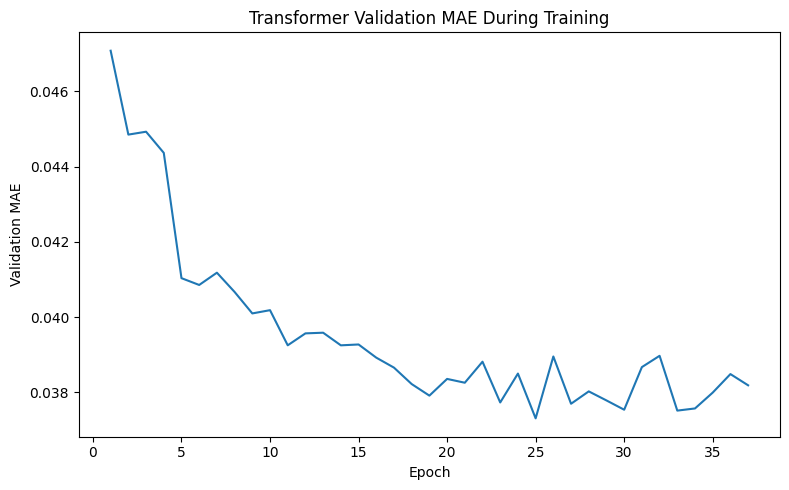

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    transformer_history_df["epoch"],
    transformer_history_df["valid_MAE"]
)

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title(
    "Transformer Validation MAE During Training"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "transformer_validation_mae.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

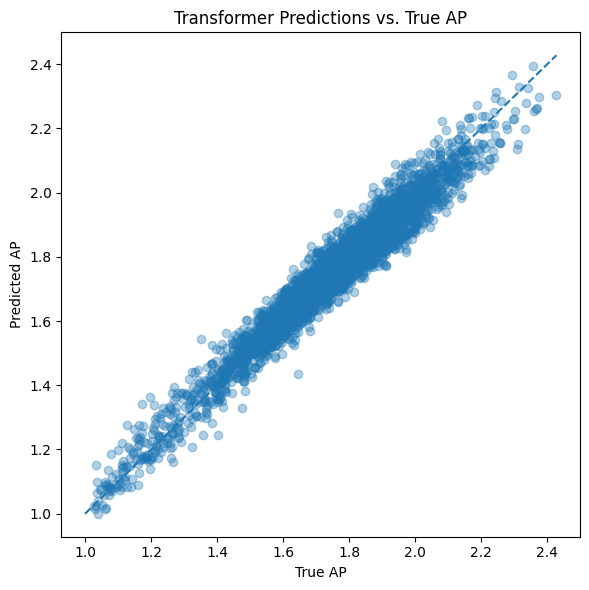

In [47]:
plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    test_predictions_transformer,
    alpha=0.35
)

minimum_value = min(
    y_test.min(),
    test_predictions_transformer.min()
)

maximum_value = max(
    y_test.max(),
    test_predictions_transformer.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("True AP")
plt.ylabel("Predicted AP")
plt.title(
    "Transformer Predictions vs. True AP"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "transformer_predictions_vs_true_ap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [48]:
prediction_comparison_df = test_df[
    ["Feature", "Label"]
].copy()

prediction_comparison_df["length"] = (
    prediction_comparison_df["Feature"]
    .str.len()
)

prediction_comparison_df["MLP_prediction"] = (
    test_predictions
)

prediction_comparison_df["LSTM_prediction"] = (
    test_predictions_lstm
)

prediction_comparison_df["Transformer_prediction"] = (
    test_predictions_transformer
)

for model_name in [
    "MLP",
    "LSTM",
    "Transformer"
]:
    prediction_comparison_df[
        f"{model_name}_residual"
    ] = (
        prediction_comparison_df[
            f"{model_name}_prediction"
        ]
        - prediction_comparison_df["Label"]
    )

    prediction_comparison_df[
        f"{model_name}_absolute_error"
    ] = (
        prediction_comparison_df[
            f"{model_name}_residual"
        ].abs()
    )

display(
    prediction_comparison_df.head()
)

,Feature,Label,length,MLP_prediction,LSTM_prediction,Transformer_prediction,MLP_residual,MLP_absolute_error,LSTM_residual,LSTM_absolute_error,Transformer_residual,Transformer_absolute_error
0,CNINGKN,1.392,7,1.372281,1.354889,1.395338,-0.019719,0.019719,-0.037111,0.037111,0.003338,0.003338
1,NFHKG,1.915,5,1.885705,1.873995,1.867674,-0.029295,0.029295,-0.041005,0.041005,-0.047326,0.047326
2,DLDMYL,1.568,6,1.597368,1.573920,1.637321,0.029368,0.029368,0.005920,0.005920,0.069321,0.069321
3,VSHVNDL,1.812,7,1.755282,1.796223,1.764547,-0.056718,0.056718,-0.015777,0.015777,-0.047453,0.047453
4,ESNSTHGP,1.567,8,1.613197,1.588612,1.591401,0.046197,0.046197,0.021612,0.021612,0.024401,0.024401


In [49]:
assert len(test_df) == len(test_predictions)
assert len(test_df) == len(test_predictions_lstm)
assert len(test_df) == len(test_predictions_transformer)

In [50]:
prediction_comparison_df.to_csv(
    results_dir
    / "test_predictions_all_models.csv",
    index=False
)

print("Predictions saved.")

Predictions saved.
